# Credit Card Fraud Detection: Initial Report and Exploratory Data Analysis

**Notebook 1 of 2: data understanding, cleaning, EDA and baseline model.** The advanced models, tuning and business recommendation are in `2_modeling_and_evaluation.ipynb`.

### Research question
> *Can a machine learning model flag fraudulent credit card transactions accurately enough to catch most fraud while keeping false alarms on legitimate customers low?*

### What this notebook does
Before building any serious model, I want to understand the data properly: how clean it is, how fraud differs from normal activity, and what a simple model can already achieve. That simple model becomes the benchmark that the more advanced models in notebook 2 have to beat.

### A note for the reader
Throughout the notebook, each step follows the same pattern:
- **Why this step:** the reason I'm doing it.
- **The code:** with comments explaining what each part does.
- **What I found:** the takeaway in plain language, with the actual numbers.

**Contents**
1. Setup and data loading
2. Data overview
3. Data cleaning (missing values, duplicates)
4. Exploratory data analysis
5. Outlier analysis
6. Feature engineering
7. Train/test split (time-ordered)
8. Baseline model: Logistic Regression
9. Summary of findings and next steps

## 1. Setup and Data Loading

**Why this step:** I import all the libraries up front so the reader can see at a glance which tools the analysis relies on: pandas and NumPy for data handling, seaborn and Matplotlib for charts, and scikit-learn for modeling and evaluation.

In [1]:
# --- Core data libraries ---
import numpy as np                 # numerical operations (log transforms, arrays)
import pandas as pd                # loading and manipulating the transaction table

# --- Visualization ---
import matplotlib.pyplot as plt    # base plotting library (figure layout, axes)
import seaborn as sns              # higher-level statistical plots built on Matplotlib

# --- Modeling and evaluation (scikit-learn) ---
from sklearn.pipeline import Pipeline               # chains scaling + model so they are fit together
from sklearn.preprocessing import StandardScaler    # puts all features on the same scale
from sklearn.linear_model import LogisticRegression # the baseline classifier
from sklearn.dummy import DummyClassifier           # a "do nothing" model used as a sanity check
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score, recall_score,
    f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    PrecisionRecallDisplay
)

import warnings
warnings.filterwarnings("ignore")  # hide library deprecation notices so the output stays readable

# Use one consistent visual style for every chart in the notebook
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# Fixing the random seed means anyone re-running the notebook gets the same results
RANDOM_STATE = 42

# Charts used in the README are saved to the images/ folder at the top of the repository
import os
IMAGE_DIR = "../images"
os.makedirs(IMAGE_DIR, exist_ok=True)

**Why this dataset:** I'm using the Kaggle *Credit Card Fraud Detection* dataset, which contains real transactions made by European cardholders in September 2013. It's widely used for fraud research because it reflects the real-world problem: fraud is extremely rare.

The file is about 150 MB, which is too large to store on GitHub, so it is not included in the repository. To run this notebook, download `creditcard.csv` from [Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) and put it in a `data/` folder next to this notebook.

In [2]:
# Load the raw data exactly as downloaded. I keep this untouched copy as df_raw
# so I can always compare the cleaned version against the original.
df_raw = pd.read_csv("data/creditcard.csv")

print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}")
df_raw.head()  # first five rows, to see what a transaction record looks like

Rows: 284,807 | Columns: 31


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Data Overview

**Why this step:** Before cleaning or plotting anything, I need to know what each column means and what kind of values it holds.

| Column | Description |
|---|---|
| `Time` | Seconds elapsed since the first transaction (covers about 2 days) |
| `V1`–`V28` | Anonymized features produced by PCA |
| `Amount` | Transaction amount (currency not stated in the source; see note below) |
| `Class` | Target: 1 = fraud, 0 = legitimate |

**An important limitation:** to protect cardholder privacy, the bank converted the original details (merchant, location, card type and so on) into 28 anonymous numeric features using a technique called PCA. This means I can tell *which* features help detect fraud, but not *what they represent* in the real world. `Time` and `Amount` are the only features I can interpret in plain business terms, so I give them extra attention in the EDA.

**A note on currency:** the dataset description says the cardholders were European but never names the currency of `Amount`. Throughout this project I show amounts with a € sign for readability, since euros are the most likely currency, but this is an assumption. None of the findings depend on the currency, because every pattern and model result is relative to the data itself.

In [3]:
# Column types and memory use. I'm checking that every column was read as a number
# (no text columns that would need encoding).
df_raw.info(verbose=False)

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Columns: 31 entries, Time to Class
dtypes: float64(30), int64(1)
memory usage: 67.4 MB


**What I found:** all 31 columns are numeric (30 decimal columns and the integer `Class` label), so no text encoding is needed.

In [4]:
# Summary statistics for the three columns I can interpret.
# (The V-features are already centered around zero by PCA, so their summaries aren't informative.)
df_raw[["Time", "Amount", "Class"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.86,47488.15,0.0,54201.5,84692.0,139320.50,172792.00
Amount,284807.0,88.35,250.12,0.0,5.6,22.0,77.16,25691.16
Class,284807.0,0.00,0.04,0.0,0.0,0.0,0.00,1.00


**What I found:**
- `Time` runs from 0 to about 172,800 seconds, which is 48 hours: the data covers two days.
- `Amount` is heavily skewed. The median transaction is €22, but the maximum is €25,691. A few very large purchases stretch the scale, which I deal with later using a log transform.
- The mean of `Class` is 0.00, which is the first hint of how rare fraud is.

In [5]:
# How many transactions are fraud vs. legitimate? This is the single most important
# fact about the dataset, because it shapes every modeling decision that follows.
class_counts = df_raw["Class"].value_counts()
class_pct = df_raw["Class"].value_counts(normalize=True) * 100

pd.DataFrame({"count": class_counts, "percent": class_pct.round(3)}).rename(index={0: "Legitimate", 1: "Fraud"})

,count,percent
Class,,
Legitimate,284315,99.827
Fraud,492,0.173


**What I found:** only **492 of 284,807 transactions (0.17%) are fraud**, roughly 1 in every 580.

This is called a *highly imbalanced* dataset, and it changes how the problem must be approached. A lazy model that labels every transaction "legitimate" would be 99.8% accurate while catching zero fraud. So accuracy cannot be used to judge the models; I need metrics that focus on the rare fraud cases (explained in Section 8).

## 3. Data Cleaning

**Why this step:** Models learn whatever is in the data, including errors. Missing values can break the code or bias results, and duplicate rows can make a model look better than it is.

### 3.1 Missing values

In [6]:
# Count missing values in each column, then show only columns that have at least one
missing = df_raw.isna().sum()
print(f"Total missing values: {missing.sum()}")
missing[missing > 0]   # an empty result means no column has missing data

Total missing values: 0


Series([], dtype: int64)

**What I found:** there are no missing values in any column, so no imputation (filling in gaps) is required.

### 3.2 Duplicate rows

In [7]:
# A duplicate here means two rows identical in every column: same time, same amount,
# and all 28 anonymized features matching exactly.
n_dupes = df_raw.duplicated().sum()
dupe_fraud = df_raw[df_raw.duplicated()]["Class"].sum()

print(f"Duplicate rows: {n_dupes:,} ({n_dupes / len(df_raw):.2%} of data)")
print(f"Of which fraud: {dupe_fraud}")

Duplicate rows: 1,081 (0.38% of data)
Of which fraud: 19


**What I found:** 1,081 rows (0.38%) are exact duplicates, including 19 fraud cases.

**My decision: remove them.** Two genuinely separate transactions matching to the same second on all 30 values is extremely unlikely, so these are almost certainly repeated records. Keeping them is risky for a second reason: when I split the data into training and test sets, a copy could land in each. The model would then be "tested" on a transaction it has already seen, which inflates its score.

In [8]:
# Drop the duplicates and reset the row numbering so it runs 0, 1, 2, ... again.
# From here on, df is the clean dataset used for all analysis.
df = df_raw.drop_duplicates().reset_index(drop=True)

print(f"Rows after removing duplicates: {len(df):,}")
print(f"Fraud cases after removing duplicates: {df['Class'].sum()} ({df['Class'].mean():.3%})")

Rows after removing duplicates: 283,726
Fraud cases after removing duplicates: 473 (0.167%)


**Result:** the clean dataset has **283,726 transactions, of which 473 are fraud (0.167%)**.

## 4. Exploratory Data Analysis

**Why this step:** EDA is where I look for patterns that separate fraud from normal behavior. Anything I find here can guide feature engineering, and it also helps me explain the final model's decisions to a non-technical audience.

### 4.1 Class distribution

I show the same counts twice. On a normal (linear) scale the fraud bar is so small it's practically invisible, which makes the imbalance obvious. On a log scale each step up the axis is 10 times larger, so both bars become visible and comparable.

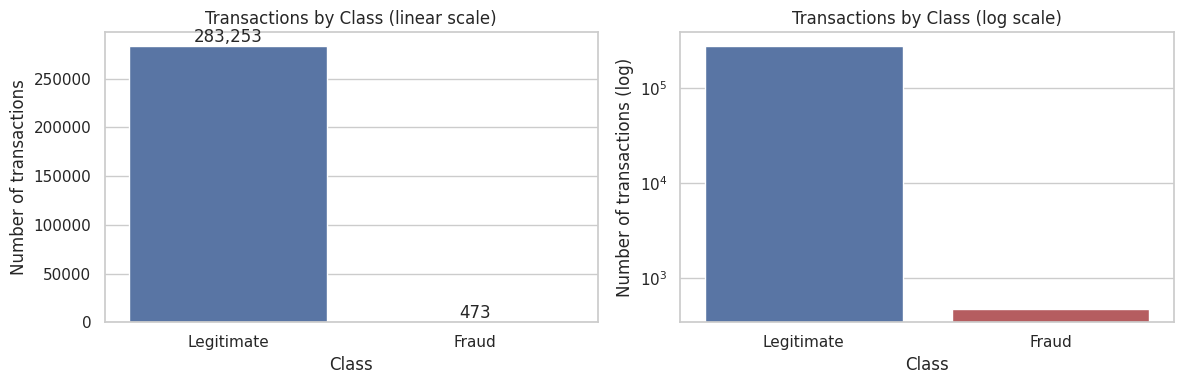

In [9]:
# Two side-by-side charts sharing the same data, so the reader can compare the scales
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Translate 0/1 into readable labels for the x-axis
counts = df["Class"].map({0: "Legitimate", 1: "Fraud"}).value_counts()

# Left: linear scale (shows how dominant the legitimate class is)
sns.barplot(x=counts.index, y=counts.values, palette=["#4C72B0", "#C44E52"], ax=axes[0])
axes[0].set_title("Transactions by Class (linear scale)")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Number of transactions")
for i, v in enumerate(counts.values):          # write the exact count above each bar
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")

# Right: log scale (makes the tiny fraud bar visible)
sns.barplot(x=counts.index, y=counts.values, palette=["#4C72B0", "#C44E52"], ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Transactions by Class (log scale)")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Number of transactions (log)")

plt.tight_layout()
plt.savefig(f"{IMAGE_DIR}/class_distribution.png", bbox_inches="tight")   # used in the README
plt.show()

**What I found:** on the linear chart, 473 fraud cases barely register next to 283,253 legitimate ones. This picture is the clearest way to explain to a non-technical audience why fraud detection is hard: it's a search for a few needles in a very large haystack.

### 4.2 Transaction amount

**Why this step:** `Amount` is one of only two features I can interpret, so I want to know whether fraudsters spend differently from genuine cardholders. A business audience can act on findings like this directly, for example by setting rules for very small charges.

In [10]:
# Side-by-side summary statistics of amount for each class
df.groupby("Class")["Amount"].describe().rename(index={0: "Legitimate", 1: "Fraud"}).round(2)

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
Legitimate,283253.0,88.41,250.38,0.0,5.67,22.00,77.46,25691.16
Fraud,473.0,123.87,260.21,0.0,1.00,9.82,105.89,2125.87


**What I found:** fraud has a *higher* average amount (€124 vs €88) but a much *lower* median (€9.82 vs €22). When the average and median move in opposite directions, the distribution is lopsided: many fraud transactions are tiny, while a few large ones pull the average up. The charts below show this.

**How to read the two charts below:**
- **Left (histogram):** I plot `log(1 + Amount)` instead of raw amount because the raw values are so skewed that almost everything would be squashed against zero. On this axis, 0 means €0, about 0.7 means €1, about 2.3 means €9, and about 4.6 means €99.
- I use **density** scaling, which rescales each class so its bars cover the same total area. Without it, the fraud bars would be about 600 times shorter than the legitimate bars and invisible. **Fraud looks as large as legitimate activity here only because of this rescaling; it is still 0.17% of transactions.** The chart compares the *shape* of the two distributions, not their size.
- **Right (box plot):** each box summarizes one class on its own. The middle line is the median, the box covers the middle 50% of transactions, and circles are unusually large amounts. Both boxes are drawn the same width regardless of how many transactions they represent.

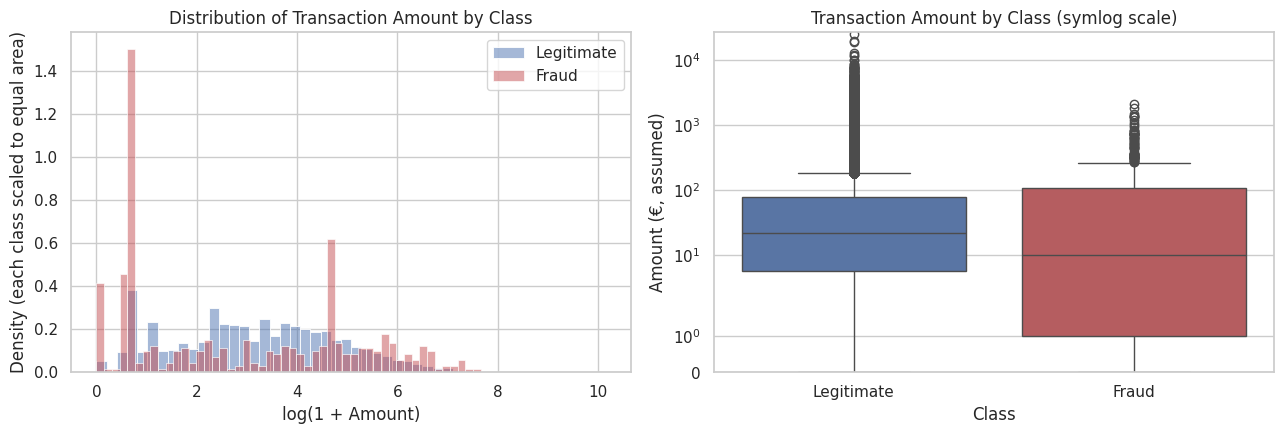

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: histogram of log-amount for each class.
# stat="density" makes each class's bars sum to the same area, so the small fraud class
# can be compared with the large legitimate class on equal terms.
for cls, color, label in [(0, "#4C72B0", "Legitimate"), (1, "#C44E52", "Fraud")]:
    sns.histplot(np.log1p(df.loc[df["Class"] == cls, "Amount"]), bins=50, stat="density",
                 color=color, alpha=0.5, label=label, ax=axes[0])
axes[0].set_title("Distribution of Transaction Amount by Class")
axes[0].set_xlabel("log(1 + Amount)")
axes[0].set_ylabel("Density (each class scaled to equal area)")
axes[0].legend()

# Right: box plot on a "symlog" scale. Like a log scale, it spreads out the skewed
# values, but unlike a pure log scale it can also show €0 transactions.
sns.boxplot(data=df, x=df["Class"].map({0: "Legitimate", 1: "Fraud"}), y="Amount",
            palette=["#4C72B0", "#C44E52"], ax=axes[1])
axes[1].set_yscale("symlog")
axes[1].set_ylim(bottom=0)        # amounts can't be negative, so hide the empty lower half
axes[1].set_title("Transaction Amount by Class (symlog scale)")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Amount (€, assumed)")

plt.tight_layout()
plt.show()

**What I found in the charts:**
- **The tall red spikes are real patterns, not plotting errors.** They come from a few amounts that fraudsters use over and over:

| Spike position on chart | Amount | Fraud transactions | Share of all fraud |
|---|---|---|---|
| ~0.69 (tallest) | €1.00 | 105 | 22% |
| 0 | €0.00 | 25 | 5% |
| ~0.55 | €0.76–€0.77 | 27 | 6% |
| ~4.6 | €99.99 | 27 | 6% |

  Because there are only 473 frauds, 105 transactions at exactly €1 are enough to create a very tall bar. Genuine customers spend all sorts of different amounts, so no single value dominates their distribution.
- This matches a known fraud tactic called **card testing**: a criminal makes a tiny charge to check whether a stolen card works before attempting larger purchases.
- **In the box plot**, the fraud box stretches lower (its bottom edge is €1, versus €5.67 for legitimate) and slightly higher, showing that fraud amounts are more spread out. The legitimate class shows many more outlier circles simply because it has about 600 times more transactions, and its largest purchase (€25,691) is far bigger than the largest fraud (€2,126).

In [12]:
# To put numbers on the card-testing pattern, I group transactions into amount bands
# and calculate what share of each band is fraud.
amount_bins = [-0.01, 1, 10, 50, 100, 500, 1000, df["Amount"].max()]
amount_labels = ["≤1", "1–10", "10–50", "50–100", "100–500", "500–1k", ">1k"]
df_band = df.assign(AmountBand=pd.cut(df["Amount"], bins=amount_bins, labels=amount_labels))

band_summary = df_band.groupby("AmountBand", observed=True)["Class"].agg(
    transactions="count", fraud="sum", fraud_rate="mean"
)
band_summary["fraud_rate"] = (band_summary["fraud_rate"] * 100).round(3)  # convert to %
band_summary

,transactions,fraud,fraud_rate
AmountBand,,,
≤1,30331,171,0.564
1–10,69490,67,0.096
10–50,90327,55,0.061
50–100,37179,55,0.148
100–500,47290,91,0.192
500–1k,6174,25,0.405
>1k,2935,9,0.307


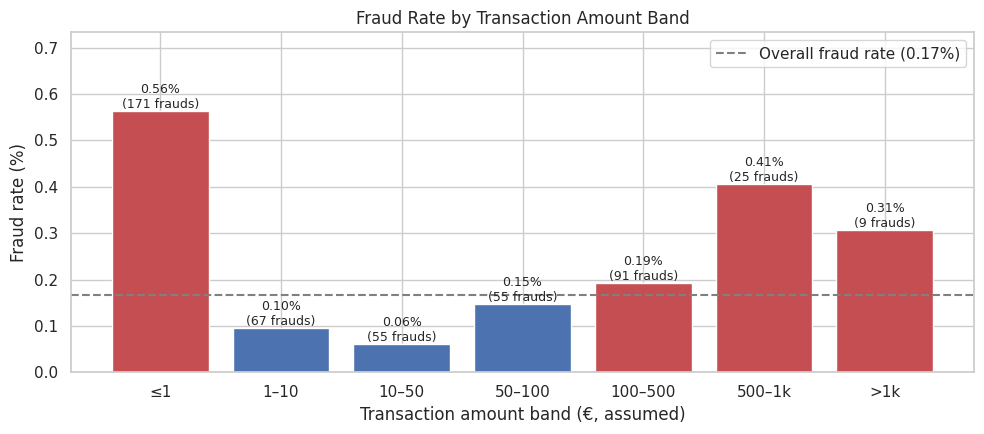

In [13]:
# Bar chart of the fraud rate in each amount band, with the overall rate as a reference line
overall_rate = df["Class"].mean() * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
bar_colors = ["#C44E52" if r > overall_rate else "#4C72B0" for r in band_summary["fraud_rate"]]
ax.bar(band_summary.index.astype(str), band_summary["fraud_rate"], color=bar_colors)
ax.axhline(overall_rate, color="grey", ls="--", label=f"Overall fraud rate ({overall_rate:.2f}%)")
for i, (rate, n) in enumerate(zip(band_summary["fraud_rate"], band_summary["fraud"])):
    ax.text(i, rate, f"{rate:.2f}%\n({n} frauds)", ha="center", va="bottom", fontsize=9)
ax.set_title("Fraud Rate by Transaction Amount Band")
ax.set_xlabel("Transaction amount band (€, assumed)")
ax.set_ylabel("Fraud rate (%)")
ax.set_ylim(0, band_summary["fraud_rate"].max() * 1.3)
ax.legend()
plt.tight_layout()
plt.savefig(f"{IMAGE_DIR}/fraud_by_amount.png", bbox_inches="tight")   # used in the README
plt.show()

**What I found:**
- Transactions of **€1 or less have a fraud rate of 0.56%, more than three times the overall rate** of 0.17%. Over a third of all fraud (36%) falls in this band.
- Larger purchases (above €500) also carry an above-average fraud rate.
- Mid-range purchases (€10–€50) are the safest.

**Business meaning:** very small charges deserve extra scrutiny, even though intuition might say large purchases are the riskiest. However, amount alone can't separate the classes, because the vast majority of small transactions are still legitimate.

### 4.3 Time of day

**Why this step:** if fraud happens at different times from normal shopping, the time of a transaction becomes a useful warning sign. The raw `Time` column only counts seconds from the start of the dataset, so I convert it into an hour of the day (0–23).

**How to read the chart:** the blue bars show how many transactions happen in each hour (left axis). The red line shows what percentage of those transactions are fraud (right axis). The dataset doesn't state the exact clock time when it starts, so "hour 0" is relative, but the pattern clearly follows a day/night cycle.

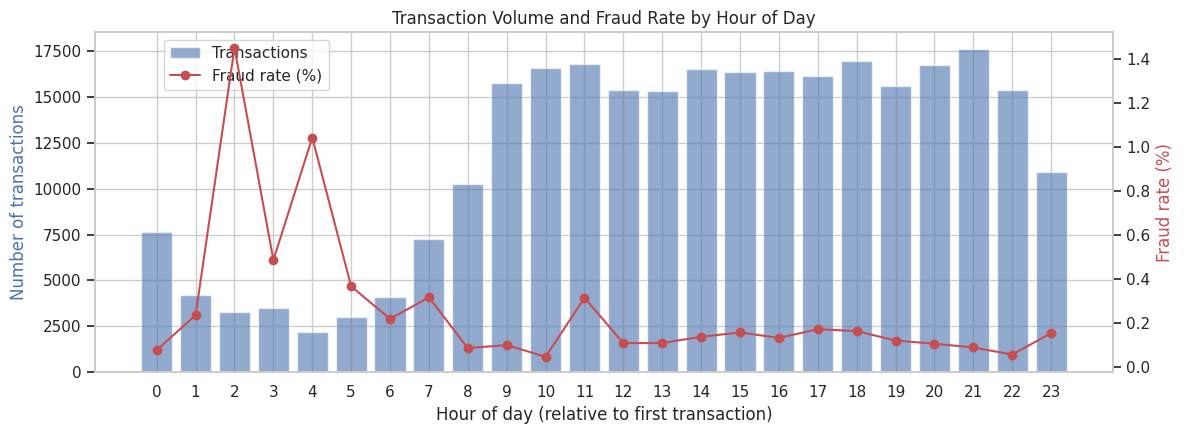

In [14]:
# Convert seconds into hour of day: divide by 3,600 seconds per hour, then use
# remainder after dividing by 24 so day 2 maps back onto hours 0-23.
hour = (df["Time"] // 3600) % 24

# For each hour, count transactions and frauds, then compute the fraud rate
hourly = df.assign(Hour=hour).groupby("Hour")["Class"].agg(transactions="count", fraud="sum")
hourly["fraud_rate_pct"] = hourly["fraud"] / hourly["transactions"] * 100

fig, ax1 = plt.subplots(figsize=(12, 4.5))

# Bars: transaction volume (left axis)
ax1.bar(hourly.index, hourly["transactions"], color="#4C72B0", alpha=0.6, label="Transactions")
ax1.set_xlabel("Hour of day (relative to first transaction)")
ax1.set_ylabel("Number of transactions", color="#4C72B0")
ax1.set_xticks(range(0, 24))

# Line: fraud rate (second y-axis on the right, because it's on a very different scale)
ax2 = ax1.twinx()
ax2.plot(hourly.index, hourly["fraud_rate_pct"], color="#C44E52", marker="o", label="Fraud rate (%)")
ax2.set_ylabel("Fraud rate (%)", color="#C44E52")
ax2.grid(False)   # avoid two overlapping sets of grid lines

ax1.set_title("Transaction Volume and Fraud Rate by Hour of Day")
handles = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(handles, ["Transactions", "Fraud rate (%)"], loc="upper left", bbox_to_anchor=(0.06, 1.0))
plt.tight_layout()
plt.savefig(f"{IMAGE_DIR}/fraud_by_hour.png", bbox_inches="tight")   # used in the README
plt.show()

**What I found:** normal shopping drops sharply during hours 1–7, which is most likely night time. Fraud doesn't drop nearly as much, so **the fraud rate jumps during the quiet night hours**, peaking at about 1.45% in hour 2. That's nearly 9 times the overall rate.

**Business meaning:** a transaction at 2 a.m. is far riskier than one in the afternoon. This is a pattern worth giving the model directly, so I turn it into a feature in Section 6.

### 4.4 Which anonymized features separate fraud from legitimate transactions?

**Why this step:** I can't interpret `V1`–`V28` directly, but I can still measure how strongly each one is related to fraud. Correlation ranges from -1 to +1: values far from zero mean the feature moves together with fraud (positive) or in the opposite direction (negative); values near zero mean no linear relationship.

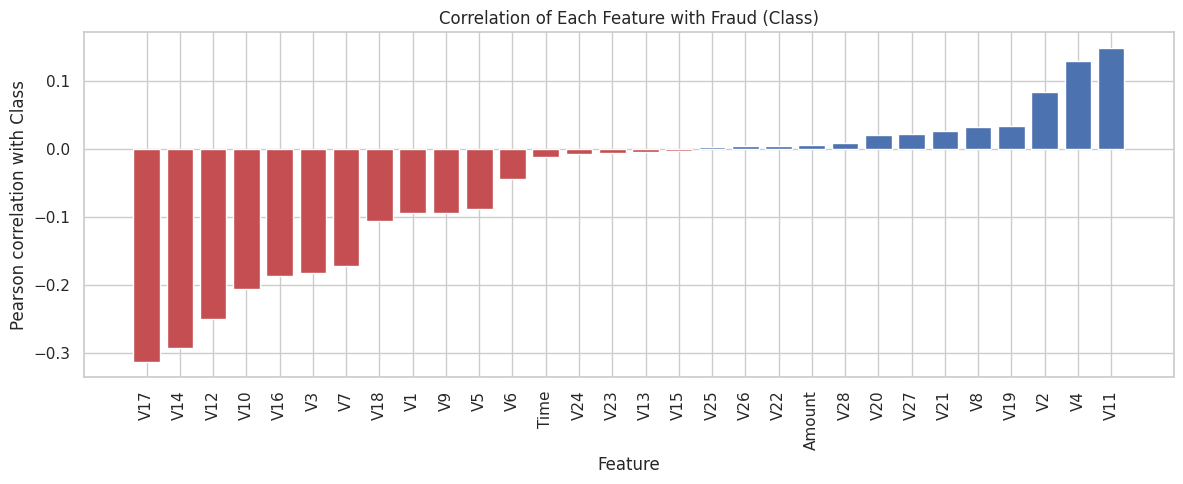

In [15]:
# Correlation between each feature and the fraud label, sorted from most negative to most positive
corr_with_class = df.drop(columns="Class").corrwith(df["Class"]).sort_values()

fig, ax = plt.subplots(figsize=(12, 5))
# Red bars = negative relationship, blue bars = positive relationship
colors = ["#C44E52" if v < 0 else "#4C72B0" for v in corr_with_class.values]
ax.bar(corr_with_class.index, corr_with_class.values, color=colors)
ax.set_title("Correlation of Each Feature with Fraud (Class)")
ax.set_xlabel("Feature")
ax.set_ylabel("Pearson correlation with Class")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

**What I found:** a handful of features stand out, mostly with negative correlations (V17, V14, V12, V10, V16, V3). A negative correlation means fraud transactions tend to have *lower* values on these features. `Amount` and `Time` show almost no linear relationship with fraud, which supports the earlier finding that amount alone is a weak signal.

A correlation of around 0.3 may look small, but with fraud being so rare it is meaningful. To see this more clearly, I plot the distributions of the six strongest features for each class.

**How to read the next chart:** each panel shows a smoothed curve for legitimate (blue) and fraud (red) transactions. As with the amount histogram, each curve is scaled to the same area so the shapes can be compared. **The less the two curves overlap, the better that feature separates fraud from legitimate activity.**

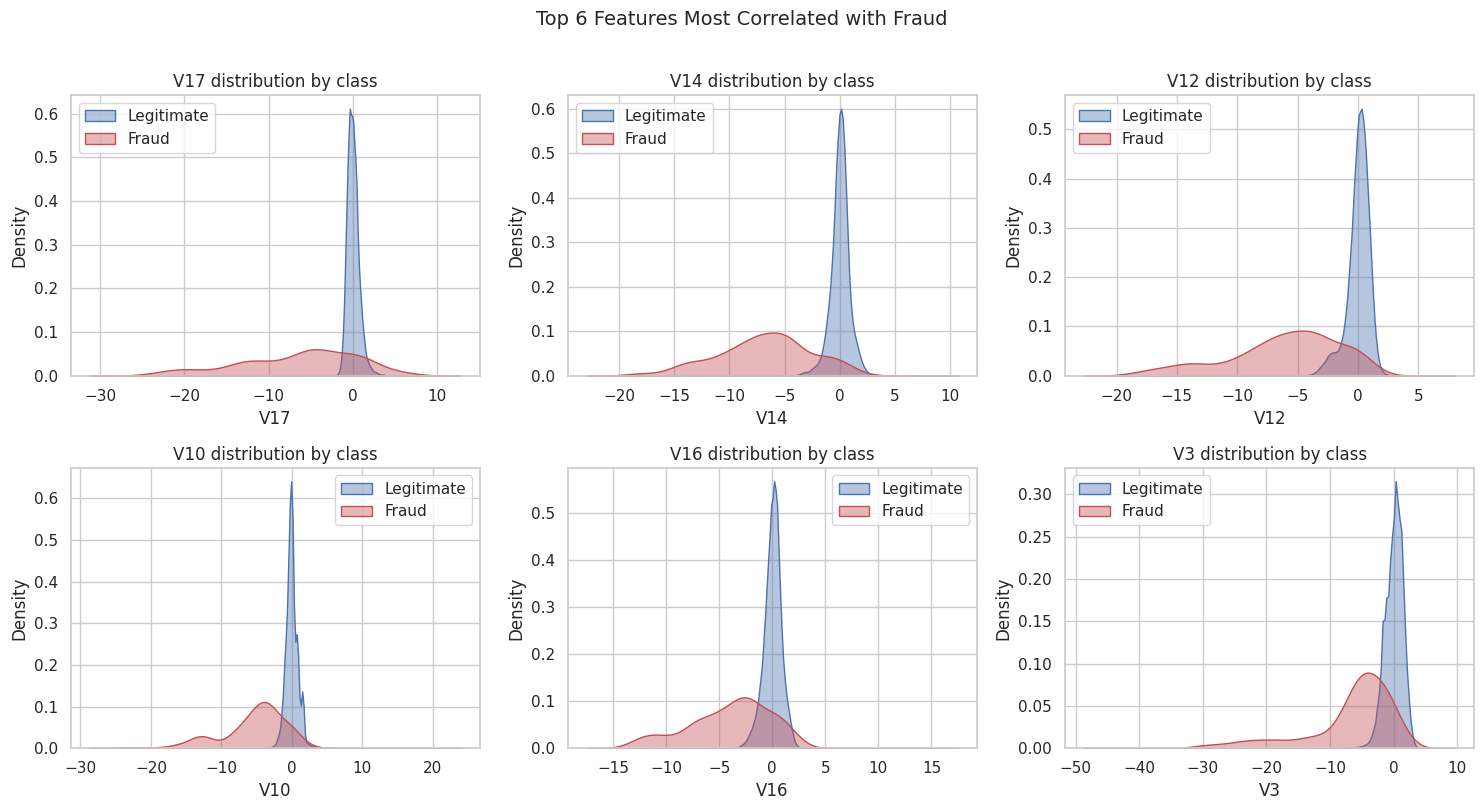

In [16]:
# Pick the six features with the strongest correlation (ignoring the sign)
top_features = corr_with_class.abs().sort_values(ascending=False).head(6).index.tolist()

# 2 rows x 3 columns of panels, one per feature
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feat in zip(axes.flat, top_features):
    for cls, color, label in [(0, "#4C72B0", "Legitimate"), (1, "#C44E52", "Fraud")]:
        # common_norm=False scales each class's curve separately (equal area each)
        sns.kdeplot(df.loc[df["Class"] == cls, feat], fill=True, alpha=0.4,
                    color=color, label=label, ax=ax, common_norm=False)
    ax.set_title(f"{feat} distribution by class")
    ax.set_xlabel(feat)
    ax.set_ylabel("Density")
    ax.legend()
plt.suptitle("Top 6 Features Most Correlated with Fraud", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

**What I found:** for features like V14, V17 and V12, the legitimate curve is a tall narrow peak around zero, while the fraud curve is flatter and shifted well to the left. Most fraud sits in a region where legitimate transactions are rare. This is exactly the kind of separation a model can learn from.

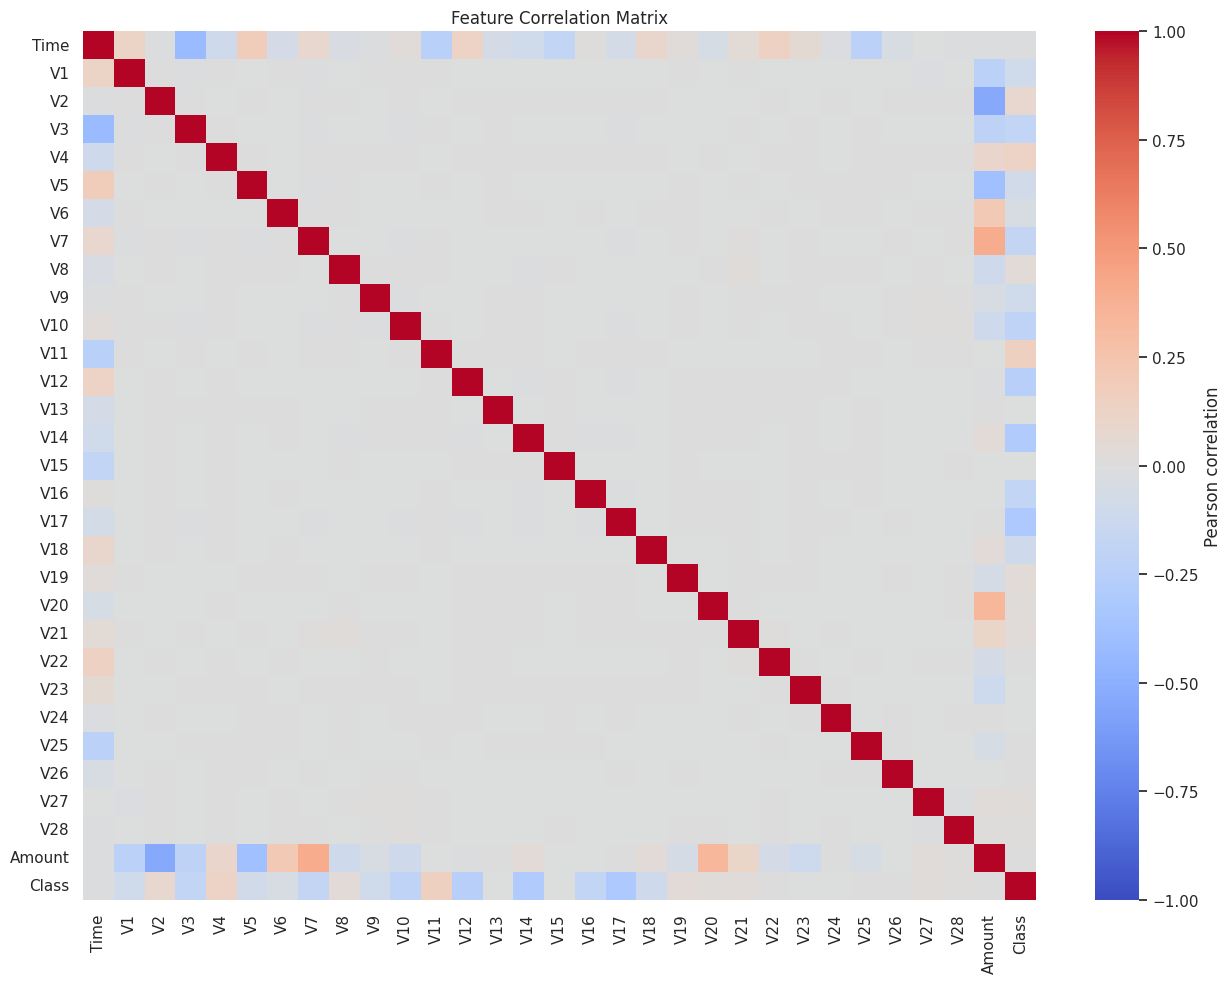

In [17]:
# Full correlation matrix: every feature against every other feature.
# I'm checking whether any features are strongly related to each other (multicollinearity),
# which can make Logistic Regression coefficients unstable.
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(df.corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1,
            cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

**How to read the heatmap:** each square shows the correlation between two features. Dark red is strong positive, dark blue is strong negative, and pale is close to zero. The diagonal is always dark red because every feature correlates perfectly with itself.

**What I found:** apart from the diagonal, the V-features are almost entirely pale. That's expected: PCA builds its components to be independent of one another. This is good news for Logistic Regression, because there's no multicollinearity to worry about. `Amount` and `Time` do show some correlation with a few V-features, which is also expected since the V-features were derived from the original transaction details.

## 5. Outlier Analysis

**Why this step:** outliers are values far from the typical range. In many projects they're treated as errors and removed. In fraud detection I need to be careful, because fraud itself is *unusual behavior*, so some outliers may be exactly what I'm trying to catch. Before deciding what to do with them, I check how fraud is distributed among them.

I use two standard methods:
1. **IQR method on `Amount`:** anything more than 1.5 times the interquartile range above the upper quartile is flagged as an outlier. This is the same rule a box plot uses to draw its circles.
2. **Z-score method on `V1`–`V28`:** a z-score measures how many standard deviations a value sits from the average. I flag any transaction where at least one feature is more than 4 standard deviations away, which is very extreme.

In [18]:
# IQR method: Q1 and Q3 are the 25th and 75th percentiles; IQR is the spread between them
q1, q3 = df["Amount"].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr            # anything above this is an amount outlier
is_amount_outlier = df["Amount"] > upper_fence

print(f"Amount IQR upper fence: €{upper_fence:,.2f}")
print(f"Amount outliers: {is_amount_outlier.sum():,} ({is_amount_outlier.mean():.2%} of transactions)")
print(f"Fraud rate among amount outliers: {df.loc[is_amount_outlier, 'Class'].mean():.3%}")
print(f"Fraud rate among non-outliers:   {df.loc[~is_amount_outlier, 'Class'].mean():.3%}")

Amount IQR upper fence: €185.38
Amount outliers: 31,685 (11.17% of transactions)
Fraud rate among amount outliers: 0.275%
Fraud rate among non-outliers:   0.153%


**What I found:** any amount above €185 counts as an outlier, which covers 11% of transactions. That's a lot of "outliers," a reminder that the IQR rule just reflects how skewed spending is; large purchases are normal. These higher-value transactions have a somewhat higher fraud rate (0.28% vs 0.15%), but the difference is modest.

In [19]:
# Z-score method: standardize every V-feature, then count how many extreme values
# (more than 4 standard deviations from the mean) each transaction has
v_cols = [f"V{i}" for i in range(1, 29)]
z_scores = (df[v_cols] - df[v_cols].mean()) / df[v_cols].std()
extreme_count = (z_scores.abs() > 4).sum(axis=1)
has_extreme = extreme_count > 0         # True if the transaction has at least one extreme value

# Compare fraud rates for transactions with and without extreme values
outlier_summary = pd.DataFrame({
    "transactions": [(~has_extreme).sum(), has_extreme.sum()],
    "fraud": [df.loc[~has_extreme, "Class"].sum(), df.loc[has_extreme, "Class"].sum()],
}, index=["No extreme V-value", "≥1 extreme V-value (|z| > 4)"])
outlier_summary["fraud_rate_pct"] = (outlier_summary["fraud"] / outlier_summary["transactions"] * 100).round(3)
outlier_summary

,transactions,fraud,fraud_rate_pct
No extreme V-value,270113,66,0.024
≥1 extreme V-value (|z| > 4),13613,407,2.990


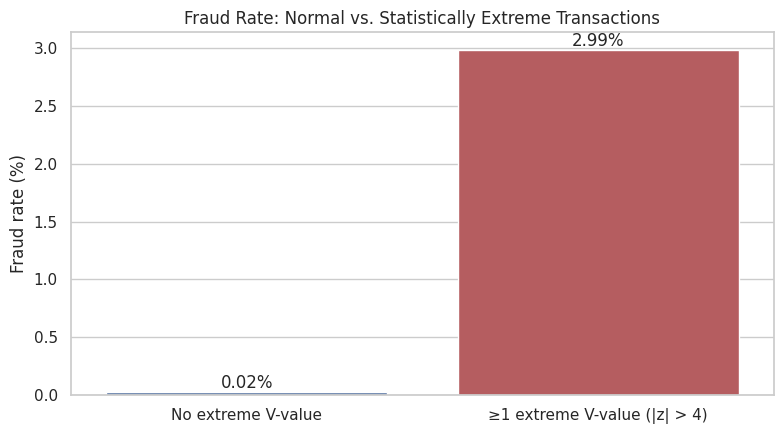

In [20]:
# Visualize the fraud-rate gap between normal and extreme transactions
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=outlier_summary.index, y=outlier_summary["fraud_rate_pct"], palette=["#4C72B0", "#C44E52"], ax=ax)
ax.set_title("Fraud Rate: Normal vs. Statistically Extreme Transactions")
ax.set_xlabel("")
ax.set_ylabel("Fraud rate (%)")
for i, v in enumerate(outlier_summary["fraud_rate_pct"]):   # label each bar with its value
    ax.text(i, v, f"{v:.2f}%", ha="center", va="bottom")
plt.tight_layout()
plt.show()

**What I found:** this is one of the most striking results in the analysis. The **4.8% of transactions with at least one extreme feature value contain 86% of all fraud** (407 of 473). Their fraud rate is 2.99%, more than 100 times the 0.024% rate of the remaining transactions.

**My decision: keep all outliers.** In this problem, **fraud *is* the anomaly**. Removing statistically unusual transactions would throw away most of the fraud and leave the model almost nothing to learn from. Instead I limit outliers' influence in other ways: scaling features before modeling now, and testing tree-based models, which are naturally less sensitive to extreme values, in notebook 2.

This finding also supports my plan to test **unsupervised anomaly detection** (Isolation Forest, One-Class SVM) later. Those methods flag unusual transactions without needing fraud labels, and this result suggests "unusual" and "fraudulent" overlap heavily.

## 6. Feature Engineering

**Why this step:** feature engineering means creating new columns that make patterns easier for a model to see. A model only sees the numbers it's given. The raw `Time` column, for example, doesn't tell it that 2 a.m. is risky; it just sees "seconds since the start." Each new feature below comes directly from a pattern I found in the EDA.

In [21]:
# Work on a copy so the cleaned dataset (df) stays unchanged
df_fe = df.copy()

# Hour: hour of day (0-23). Captures the night-time spike in fraud rate (Section 4.3).
df_fe["Hour"] = (df_fe["Time"] // 3600) % 24

# IsNight: 1 if the transaction falls in hours 1-7, the low-volume, high-fraud-rate window.
# A simple yes/no flag is easy for a linear model like Logistic Regression to use.
df_fe["IsNight"] = df_fe["Hour"].between(1, 7).astype(int)

# LogAmount: log(1 + Amount). Compresses the long tail of large purchases so a few huge
# transactions don't dominate. The "+1" avoids log(0) for €0 transactions.
df_fe["LogAmount"] = np.log1p(df_fe["Amount"])

# IsMicroAmount: 1 if the amount is €1 or less, capturing the card-testing pattern (Section 4.2).
df_fe["IsMicroAmount"] = (df_fe["Amount"] <= 1).astype(int)

# Check: do the new features actually differ between fraud and legitimate transactions?
new_features = ["Hour", "IsNight", "LogAmount", "IsMicroAmount"]
df_fe[new_features + ["Class"]].groupby("Class").mean().rename(index={0: "Legitimate", 1: "Fraud"}).round(3)

,Hour,IsNight,LogAmount,IsMicroAmount
Class,,,,
Legitimate,14.050,0.097,3.154,0.106
Fraud,11.655,0.298,2.838,0.362


**What I found:** the new features behave as the EDA predicted:
- **30% of fraud happens at night**, versus 10% of legitimate transactions (the `IsNight` averages are 0.298 and 0.097).
- **36% of fraud is a micro amount** of €1 or less, versus 11% of legitimate transactions.

Both flags are roughly three times more common among fraud, so they should help the model.

**A check on my own choice:** I picked the €1 cut-off and the night-time hours after looking at the whole dataset, including the transactions that later become the test set. To make sure I didn't build features around patterns that only exist in the test period, the next cell repeats the comparison using only the training period (the earliest 80% of transactions).

In [22]:
# Recompute the two flags' fraud rates using only the earliest 80% of transactions (the training period)
train_period = df_fe.sort_values("Time").iloc[: int(len(df_fe) * 0.8)]
check = pd.DataFrame({
    "Fraud rate when flag = 1 (%)": [train_period.loc[train_period[f] == 1, "Class"].mean() * 100 for f in ["IsMicroAmount", "IsNight"]],
    "Fraud rate when flag = 0 (%)": [train_period.loc[train_period[f] == 0, "Class"].mean() * 100 for f in ["IsMicroAmount", "IsNight"]],
}, index=["IsMicroAmount (≤ €1)", "IsNight (hours 1–7)"]).round(3)
check["Times riskier"] = (check.iloc[:, 0] / check.iloc[:, 1]).round(1)
check

,Fraud rate when flag = 1 (%),Fraud rate when flag = 0 (%),Times riskier
IsMicroAmount (≤ €1),0.597,0.126,4.7
IsNight (hours 1–7),0.513,0.129,4.0


**What I found:** both patterns hold in the training period on its own. Micro amounts of €1 or less have a fraud rate of 0.60% versus 0.13% for other transactions (4.7 times riskier), and night-time transactions have 0.51% versus 0.13% (4.0 times riskier). So these features capture genuine, stable behavior rather than something specific to the test period.

**Why the log transform matters:** the chart below shows `Amount` before and after the transform. *Skew* measures how lopsided a distribution is; 0 is perfectly symmetric. Many models, Logistic Regression included, work better when features aren't extremely skewed.

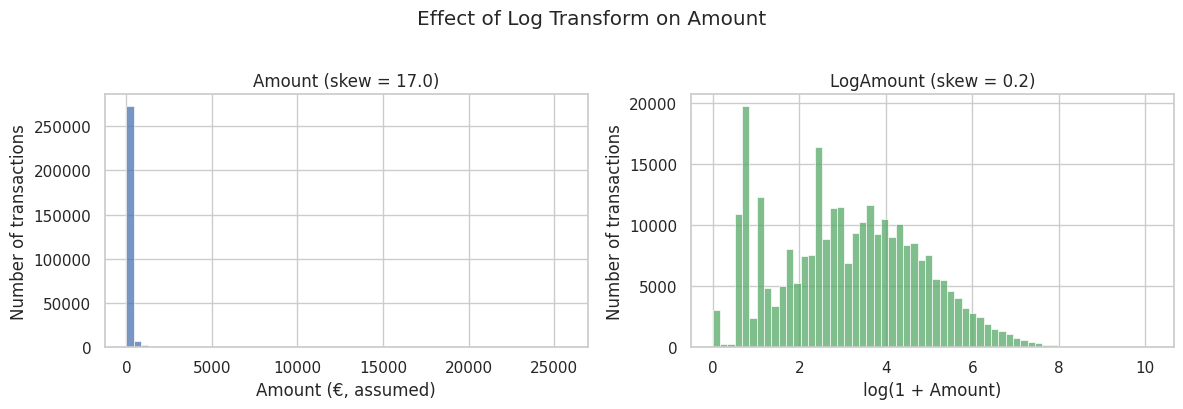

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: original amount, squashed against zero by a few very large purchases
sns.histplot(df_fe["Amount"], bins=60, color="#4C72B0", ax=axes[0])
axes[0].set_title(f"Amount (skew = {df_fe['Amount'].skew():.1f})")
axes[0].set_xlabel("Amount (€, assumed)")
axes[0].set_ylabel("Number of transactions")

# Right: after log transform, the values spread out into a much more even shape
sns.histplot(df_fe["LogAmount"], bins=60, color="#55A868", ax=axes[1])
axes[1].set_title(f"LogAmount (skew = {df_fe['LogAmount'].skew():.1f})")
axes[1].set_xlabel("log(1 + Amount)")
axes[1].set_ylabel("Number of transactions")

plt.suptitle("Effect of Log Transform on Amount", y=1.02)
plt.tight_layout()
plt.show()

**What I found:** the skew drops from about 17 to 0.2, close to symmetric. The transformed amount is far more evenly spread, which makes it much easier for the model to use.

**Final feature set for modeling:** `V1`–`V28`, `LogAmount`, `Hour`, `IsNight`, `IsMicroAmount` (32 features).
- **Raw `Time` is dropped.** It only records where a transaction falls within this particular 2-day window. A model that learned "transactions around second 150,000 are risky" would be useless on next month's data. `Hour` keeps the useful part of the information.
- **Raw `Amount` is replaced by `LogAmount`.**
- All features are standardized (rescaled to mean 0, standard deviation 1) inside the model pipeline in Section 8.

## 7. Train/Test Split (Time-Ordered)

**Why this step:** to judge a model fairly, I test it on transactions it never saw during training.

The usual approach is to split the data randomly, but that doesn't match how fraud detection works in practice. A bank trains its model on *past* transactions and then uses it to score *future* ones. With a random split, the model could learn from transactions on day 2 and then be tested on day 1, effectively "seeing the future," which makes results look better than they'd be in real use.

So I sort the transactions by time, **train on the first 80% and test on the last 20%**.

In [24]:
# The 32 features chosen in Section 6
feature_cols = v_cols + ["LogAmount", "Hour", "IsNight", "IsMicroAmount"]

# Sort chronologically, then cut at the 80% mark
df_sorted = df_fe.sort_values("Time").reset_index(drop=True)
split_idx = int(len(df_sorted) * 0.8)
train, test = df_sorted.iloc[:split_idx], df_sorted.iloc[split_idx:]

# X = input features, y = the fraud label the model must predict
X_train, y_train = train[feature_cols], train["Class"]
X_test, y_test = test[feature_cols], test["Class"]

# Confirm both sets contain enough fraud cases to learn from and evaluate on
split_summary = pd.DataFrame({
    "rows": [len(train), len(test)],
    "fraud": [y_train.sum(), y_test.sum()],
    "fraud_rate_pct": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["Train (first 80%)", "Test (last 20%)"]).round(3)
split_summary

,rows,fraud,fraud_rate_pct
Train (first 80%),226980,399,0.176
Test (last 20%),56746,74,0.130


**What I found:** the training set has 226,980 transactions with 399 frauds, and the test set has 56,746 transactions with 74 frauds.

The test set's fraud rate (0.13%) is a little lower than the training set's (0.18%). With a random split I could have forced the rates to match, but this natural shift over time is realistic: fraud levels change from week to week, and a good model has to cope with that.

## 8. Baseline Model: Logistic Regression

**Why this step:** a baseline is a simple, well-understood model that sets the bar the more advanced models in notebook 2 must clear. If a complex model can't beat it, the extra complexity isn't worth it.

I chose **Logistic Regression** because it's fast, transparent (each feature gets a coefficient showing how it pushes the prediction), and a standard starting point for yes/no classification problems like fraud vs. legitimate. It outputs a *probability* of fraud for each transaction, which I use later to explore different alert thresholds.

### 8.1 Choosing the evaluation metric

**Primary metric: Precision-Recall AUC (PR-AUC), also called Average Precision.**

To explain it, I first need two simpler ideas, both of which map directly to business outcomes:
- **Recall:** of all the real fraud, what share did the model catch? Low recall means **fraud slips through** and the bank loses money.
- **Precision:** of all the transactions the model flagged, what share were really fraud? Low precision means **many false alarms**: genuine customers get declined and the review team wastes time.

There is always a trade-off. Flagging more transactions catches more fraud but also produces more false alarms. **PR-AUC summarizes this trade-off across every possible alert threshold into one number** between 0 and 1. Higher is better.

**Why not the other common metrics?**
- **Accuracy** is misleading here. A model that never flags fraud is 99.8% accurate, as the dummy model below demonstrates.
- **ROC-AUC** is popular but tends to look excellent even for weak fraud models. It measures false alarms as a share of all legitimate transactions, and since there are so many legitimate transactions, even thousands of false alarms look like a tiny percentage.
- **PR-AUC** focuses entirely on how well the rare fraud cases are handled. It also has a meaningful floor: random guessing scores about the fraud rate (around 0.0013 on this test set), so any score well above that reflects real skill.

### 8.2 Models compared
1. **Dummy classifier:** always predicts "legitimate." It's a sanity check that shows why accuracy fails.
2. **Logistic Regression (standard):** treats every mistake as equally costly.
3. **Logistic Regression (class-weighted):** tells the model that missing a fraud case is far more costly than a false alarm. scikit-learn's `class_weight="balanced"` sets this automatically based on how rare fraud is (here, a missed fraud counts about 570 times more than a false alarm). This is one of the simplest ways to handle imbalance.

In [25]:
def evaluate(model, name, X_tr, y_tr, X_te, y_te):
    """Train a model, then score it on the test set.

    Returns a dictionary of metrics so results from several models
    can be collected into one comparison table.
    """
    model.fit(X_tr, y_tr)                       # learn from the training data
    y_pred = model.predict(X_te)                # yes/no decision at the default 0.5 threshold
    y_score = model.predict_proba(X_te)[:, 1]   # probability of fraud (needed for PR-AUC and ROC-AUC)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_te, y_pred),
        "PR-AUC": average_precision_score(y_te, y_score),
        "ROC-AUC": roc_auc_score(y_te, y_score),
        "Precision": precision_score(y_te, y_pred, zero_division=0),
        "Recall": recall_score(y_te, y_pred),
        "F1": f1_score(y_te, y_pred),           # single score balancing precision and recall
    }

# Each Logistic Regression is wrapped in a Pipeline with a scaler. This guarantees the
# scaler only learns from training data, so no information from the test set leaks in.
models = {
    "Dummy (always legitimate)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "Logistic Regression (class-weighted)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
}

# Train and evaluate all three models, collecting results in one table
results = pd.DataFrame([evaluate(m, n, X_train, y_train, X_test, y_test) for n, m in models.items()]).set_index("Model")
results.round(4)

,Accuracy,PR-AUC,ROC-AUC,Precision,Recall,F1
Model,,,,,,
Dummy (always legitimate),0.9987,0.0013,0.5000,0.0000,0.0000,0.0000
Logistic Regression,0.9992,0.7393,0.9811,0.8163,0.5405,0.6504
Logistic Regression (class-weighted),0.9575,0.7694,0.9864,0.0279,0.9324,0.0541


**What I found:**
- **The dummy model proves the point about accuracy.** It scores 99.87% accuracy while catching *no fraud at all* (recall = 0). Any report quoting only accuracy for a fraud model should be treated with suspicion.
- **Standard Logistic Regression** reaches a PR-AUC of **0.739**, hundreds of times better than random guessing (0.0013). At the default threshold it's cautious: 82% of its alerts are real fraud (high precision), but it catches only 54% of fraud (low recall).
- **Class-weighted Logistic Regression** has the best PR-AUC (**0.769**). It catches **93% of fraud**, but at the default threshold only 2.8% of its alerts are real fraud, so it raises a lot of false alarms.
- Notice that the class-weighted model's *accuracy* dropped to 95.75% even though it is clearly the more useful model. This is another reason accuracy is the wrong yardstick here.
- ROC-AUC is above 0.98 for both Logistic Regression models even though their precision is very different, which illustrates why I don't rely on it.

The two models make very different trade-offs at the default threshold. The confusion matrices below make that concrete.

**How to read a confusion matrix:** rows show what each transaction really was; columns show what the model predicted.
- Top-left: legitimate transactions correctly let through.
- Top-right: **false alarms** (legitimate transactions flagged as fraud).
- Bottom-left: **missed fraud**.
- Bottom-right: fraud correctly caught.

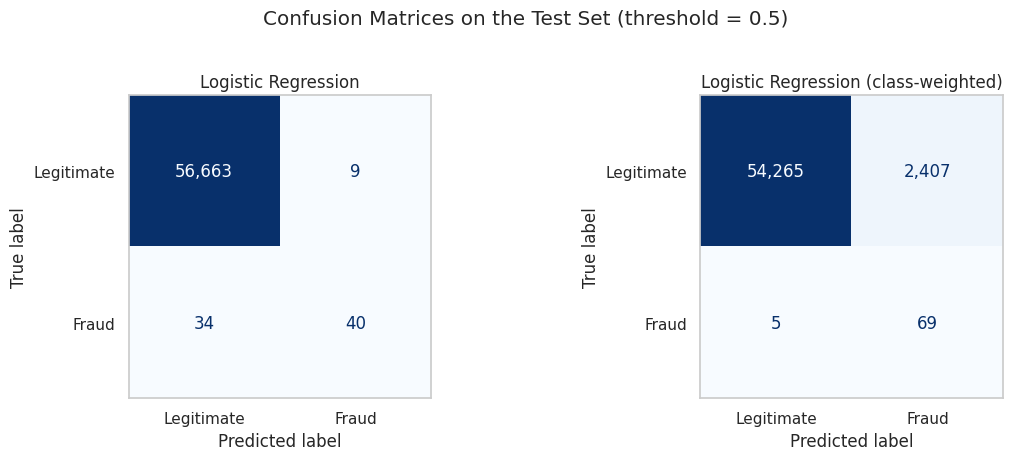

In [26]:
# Side-by-side confusion matrices for the two Logistic Regression models
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes, ["Logistic Regression", "Logistic Regression (class-weighted)"]):
    ConfusionMatrixDisplay.from_estimator(
        models[name], X_test, y_test, display_labels=["Legitimate", "Fraud"],
        cmap="Blues", values_format=",", colorbar=False, ax=ax
    )
    ax.set_title(name)
    ax.grid(False)   # grid lines would cut through the cells
plt.suptitle("Confusion Matrices on the Test Set (threshold = 0.5)", y=1.02)
plt.tight_layout()
plt.show()

**What I found:** of the 74 real frauds in the test set:
- The **standard model** catches 40 and misses 34, with only 9 false alarms.
- The **class-weighted model** catches 69 and misses just 5, but raises 2,407 false alarms.

In business terms, the standard model keeps customers happy but lets nearly half the fraud through; the class-weighted model stops almost all fraud but would swamp a review team. Neither is right at the default setting. The question is where to set the threshold, which the next two cells explore.

**How to read the precision-recall curve:** each point on a curve is one possible threshold. Moving right means catching more fraud (higher recall); moving down means more false alarms (lower precision). The ideal model would sit in the top-right corner. The dashed grey line shows what random guessing would achieve.

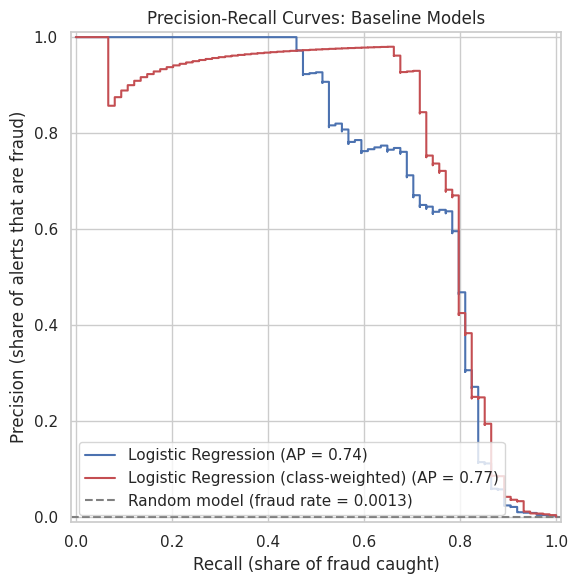

In [27]:
# Precision-recall curves for both Logistic Regression models
fig, ax = plt.subplots(figsize=(8, 6))
for name, color in [("Logistic Regression", "#4C72B0"), ("Logistic Regression (class-weighted)", "#C44E52")]:
    PrecisionRecallDisplay.from_estimator(models[name], X_test, y_test, name=name, color=color, ax=ax)

# Random-guess baseline: precision equals the fraud rate at every recall level
ax.axhline(y_test.mean(), linestyle="--", color="grey", label=f"Random model (fraud rate = {y_test.mean():.4f})")
ax.set_title("Precision-Recall Curves: Baseline Models")
ax.set_xlabel("Recall (share of fraud caught)")
ax.set_ylabel("Precision (share of alerts that are fraud)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

**What I found:** both curves sit far above the random baseline. They keep precision at around 0.7 or higher until about 70% of fraud is caught. Beyond roughly 75–80% recall, precision collapses: catching the last remaining frauds costs a huge number of false alarms. Those last frauds look very similar to legitimate transactions, and a linear model struggles to separate them. That's the gap I'll try to close with non-linear models (Random Forest, XGBoost) in notebook 2.

**Which features does the model rely on?** One advantage of Logistic Regression is that it's interpretable. Because all features were standardized, I can compare coefficients directly: a large positive coefficient pushes a transaction toward "fraud," and a large negative one pushes it toward "legitimate."

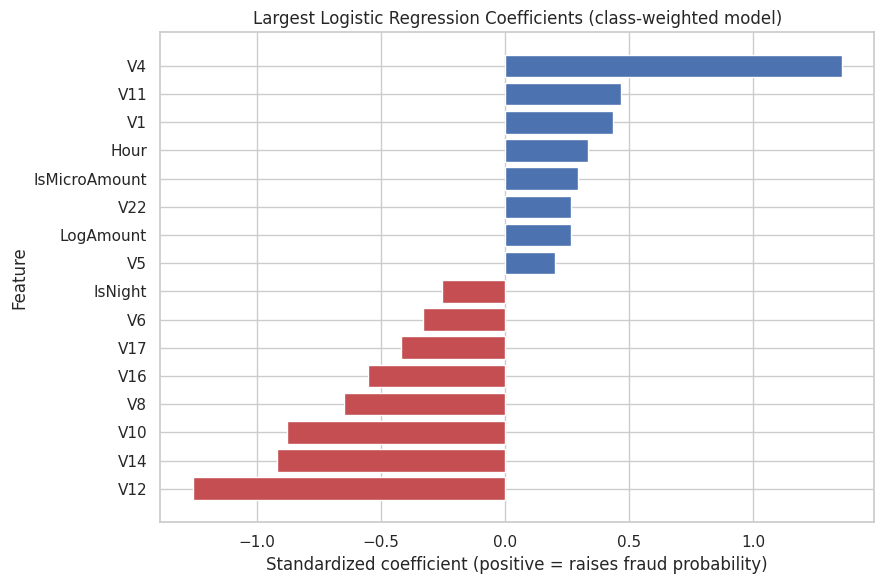

In [28]:
# Pull the trained Logistic Regression out of the pipeline to read its coefficients
lr_weighted = models["Logistic Regression (class-weighted)"].named_steps["clf"]
coefs = pd.Series(lr_weighted.coef_[0], index=feature_cols).sort_values()

# Show the 8 most negative and 8 most positive coefficients
top_coefs = pd.concat([coefs.head(8), coefs.tail(8)])

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_coefs.index, top_coefs.values, color=["#C44E52" if v < 0 else "#4C72B0" for v in top_coefs.values])
ax.set_title("Largest Logistic Regression Coefficients (class-weighted model)")
ax.set_xlabel("Standardized coefficient (positive = raises fraud probability)")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

**What I found:** V12, V14 and V10 rank near the top here, just as they did in the EDA correlations. This consistency is reassuring: the model is relying on genuine patterns rather than noise. V4 has the largest coefficient even though it wasn't among the top correlated features (see the caveat below). Because the V-features are anonymized, though, I can't translate these into business explanations, which is a limitation of this dataset.

One caveat: Logistic Regression coefficients measure each feature's effect *while holding the others constant*, so the ranking won't exactly match the simple correlations in Section 4.4.

### 8.3 Translating the model into a business decision

**Why this step:** a model doesn't decide anything on its own. It outputs a probability, and someone has to choose the cut-off above which a transaction gets flagged. The default of 0.5 is just a convention. Below, I test several thresholds for the class-weighted model and show what each would mean for a fraud operations team.

In [29]:
# Fraud probabilities for every test transaction from the class-weighted model
y_score_w = models["Logistic Regression (class-weighted)"].predict_proba(X_test)[:, 1]

rows = []
for t in [0.5, 0.8, 0.9, 0.95, 0.99, 0.999]:
    pred = (y_score_w >= t).astype(int)            # flag transactions above this threshold
    tp = ((pred == 1) & (y_test == 1)).sum()       # true positives: real fraud that was flagged
    rows.append({
        "Threshold": t,
        "Alerts raised": int(pred.sum()),          # how many transactions the team must review
        "Fraud caught": int(tp),
        "Fraud missed": int(y_test.sum() - tp),
        "False alarms": int(pred.sum() - tp),      # genuine customers inconvenienced
        "Recall": tp / y_test.sum(),
        "Precision": tp / pred.sum() if pred.sum() else 0,
    })
pd.DataFrame(rows).set_index("Threshold").round(3)

,Alerts raised,Fraud caught,Fraud missed,False alarms,Recall,Precision
Threshold,,,,,,
0.500,2476,69,5,2407,0.932,0.028
0.800,714,64,10,650,0.865,0.090
0.900,307,63,11,244,0.851,0.205
0.950,195,61,13,134,0.824,0.313
0.990,109,59,15,50,0.797,0.541
0.999,79,57,17,22,0.770,0.722


**What I found:** the threshold changes the outcome dramatically. Over the test period (the last ~8 hours of data):
- At **0.5**, the team reviews 2,476 alerts and catches 69 of 74 frauds (93%). About 35 false alarms for every real fraud.
- At **0.9**, it reviews 307 alerts and catches 63 frauds (85%).
- At **0.99**, it reviews just 109 alerts and still catches 59 frauds (80%). More than half of all alerts are real fraud.

**Business meaning:** going from 0.99 to 0.5 catches 10 more frauds but adds about 2,370 extra reviews. Whether that's worth it depends on how much a missed fraud costs compared with reviewing an alert and possibly annoying a genuine customer. **This is a business decision, not a technical one**, and in notebook 2 I'll make it explicit by assigning costs and picking the threshold that minimizes total cost.

## 9. Summary of Findings and Next Steps

The cell below prints the key figures used in this summary, so the numbers can be traced back to the code.

In [30]:
# Key numbers referenced in the summary below
best = results.loc["Logistic Regression (class-weighted)"]
base = results.loc["Logistic Regression"]
print(f"Clean dataset: {len(df):,} transactions, {df['Class'].sum()} fraud ({df['Class'].mean():.3%})")
print(f"Dummy accuracy: {results.loc['Dummy (always legitimate)', 'Accuracy']:.4f} with recall 0")
print(f"LR unweighted   -> PR-AUC {base['PR-AUC']:.3f}, recall {base['Recall']:.3f}, precision {base['Precision']:.3f}")
print(f"LR class-weight -> PR-AUC {best['PR-AUC']:.3f}, recall {best['Recall']:.3f}, precision {best['Precision']:.3f}")

Clean dataset: 283,726 transactions, 473 fraud (0.167%)
Dummy accuracy: 0.9987 with recall 0
LR unweighted   -> PR-AUC 0.739, recall 0.541, precision 0.816
LR class-weight -> PR-AUC 0.769, recall 0.932, precision 0.028


### Findings
- **Data quality:** no missing values; 1,081 duplicate rows (19 of them fraud) were removed, leaving 283,726 transactions with 473 frauds (0.167%).
- **Imbalance is the core challenge:** a model that never flags fraud scores 99.87% accuracy on the test set while catching nothing, so I rejected accuracy in favor of **PR-AUC**, supported by recall and precision.
- **When fraud happens:** fraud rates spike during low-volume night hours, up to about 1.45% in hour 2 (nearly 9 times normal).
- **How fraud spends:** 36% of fraud is €1 or less, consistent with card testing, and fraudsters reuse specific amounts such as €1.00 and €99.99.
- **Most informative features:** a handful of anonymized features (V17, V14, V12, V10) separate fraud strongly.
- **Outliers are signal, not noise:** the 4.8% of transactions with extreme feature values hold 86% of all fraud, so outliers were kept.
- **Baseline Logistic Regression** (time-ordered test set of 56,746 transactions, 74 frauds):
  - Standard: PR-AUC **0.739**; catches 54% of fraud with 82% precision.
  - Class-weighted: PR-AUC **0.769**; catches 93% of fraud, but only 2.8% of its 2,476 alerts are real fraud.
  - Raising the class-weighted model's threshold to 0.99 catches 80% of fraud with 54% precision (109 alerts). **Threshold choice is a business decision**, not a technical default.

### In plain language
A simple model can already catch most fraud. The real challenge is catching the last 10–20% without flooding the review team with false alarms, because those frauds look a lot like normal transactions. More flexible models should do better at that.

### Next steps (carried out in notebook 2)
1. Train **Random Forest and XGBoost**, which can capture non-linear patterns the linear baseline misses.
2. Compare **imbalance strategies** (class weights, SMOTE inside a pipeline, undersampling) using time-aware cross-validation.
3. Add **Isolation Forest and One-Class SVM** as unsupervised detectors for new fraud patterns with no labels yet, motivated by the outlier finding in Section 5.
4. **Choose the decision threshold by minimizing total business cost** (missed fraud amount plus a cost per false alarm).
5. **Translate the results for a non-technical audience:** fraud caught, losses prevented and alerts per day.